# Day 2: A CNN in PyTorch and the Fashion-MNIST Baseline
**Deep Learning Internship, Phase 2 (CNNs)**

> Colab: Runtime > Change runtime type > **T4 GPU** before running.

Goals: (1) load Fashion-MNIST with `torchvision` and `DataLoader`, (2) train a baseline MLP, (3) build a small CNN and track tensor shapes, (4) compare MLP vs CNN on accuracy, parameters and learning curves.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cpu


## 1. Load Fashion-MNIST
60,000 training and 10,000 test images (28x28 grayscale, 10 clothing classes). We normalise with the dataset mean/std, and keep 5,000 training images aside as a **validation set**. The test set is used only once at the end.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),   # Fashion-MNIST mean and std
])

full_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
test_set = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

train_set, val_set = random_split(full_train, [55000, 5000],
                                  generator=torch.Generator().manual_seed(42))

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

classes = full_train.classes
print("train / val / test sizes:", len(train_set), len(val_set), len(test_set))
print("classes:", classes)

images, labels = next(iter(train_loader))
print("one batch of images:", images.shape, "| labels:", labels.shape)   # [128, 1, 28, 28]

100%|██████████| 26.4M/26.4M [00:05<00:00, 4.68MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 144kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.60MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 1.67MB/s]


train / val / test sizes: 55000 5000 10000
classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
one batch of images: torch.Size([128, 1, 28, 28]) | labels: torch.Size([128])


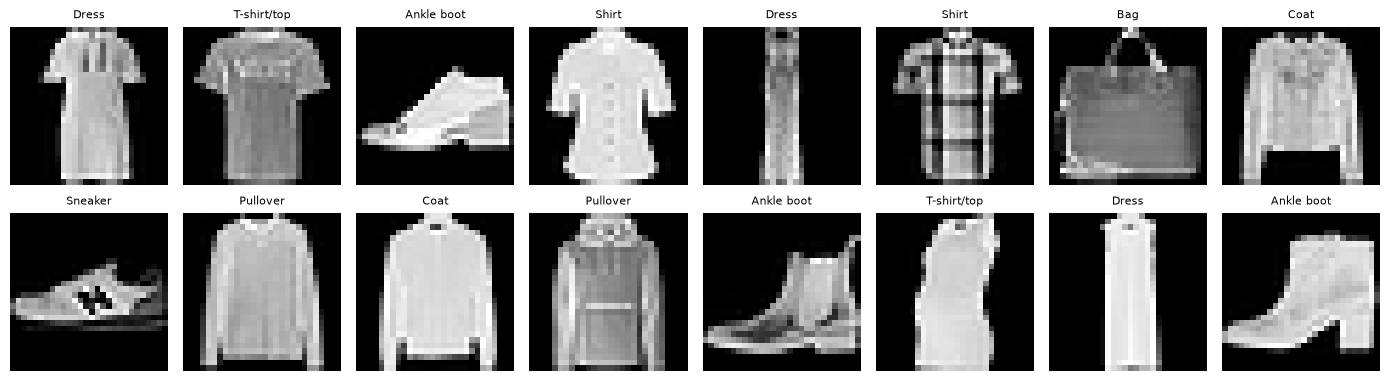

In [4]:
# Grid of sample images (un-normalise for display)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lab in zip(axes.ravel(), images, labels):
    ax.imshow(img.squeeze() * 0.3530 + 0.2860, cmap="gray")
    ax.set_title(classes[lab], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Helper functions: parameter count, training loop, evaluation

In [5]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over loader. Trains if optimizer is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total


def fit(model, epochs=10, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} "
              f"| val loss {va_loss:.4f} acc {va_acc:.4f}")
    history["time"] = time.time() - start
    return history

## 3. Baseline MLP (Phase 1 style)
Flattens the image into 784 numbers, so it loses all spatial structure.

In [6]:
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10),
)
print(mlp)
print("MLP parameters:", f"{count_params(mlp):,}")

EPOCHS = 10
mlp_hist = fit(mlp, epochs=EPOCHS)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=10, bias=True)
)
MLP parameters: 235,146
Epoch  1/10 | train loss 0.4883 acc 0.8246 | val loss 0.4011 acc 0.8534
Epoch  2/10 | train loss 0.3514 acc 0.8691 | val loss 0.3702 acc 0.8608
Epoch  3/10 | train loss 0.3125 acc 0.8837 | val loss 0.3447 acc 0.8714
Epoch  4/10 | train loss 0.2876 acc 0.8928 | val loss 0.3448 acc 0.8692
Epoch  5/10 | train loss 0.2655 acc 0.9015 | val loss 0.3186 acc 0.8844
Epoch  6/10 | train loss 0.2466 acc 0.9073 | val loss 0.3029 acc 0.8888
Epoch  7/10 | train loss 0.2333 acc 0.9136 | val loss 0.3204 acc 0.8892
Epoch  8/10 | train loss 0.2224 acc 0.9167 | val loss 0.3136 acc 0.8904
Epoch  9/10 | train loss 0.2082 acc 0.9213 | val loss 0.3254 acc 0.8902
Epoch 10/10 | train loss 0.1986 acc 0.9255 | val loss 0.3374 acc 0.

## 4. A small CNN
Two blocks of `Conv2d -> ReLU -> MaxPool2d`, then a linear classifier.
Shape tracking: `1x28x28 -> 16x28x28 -> 16x14x14 -> 32x14x14 -> 32x7x7 -> 1568 -> 64 -> 10`
(`padding=1` with a 3x3 kernel keeps the size, each pool halves it.)

In [7]:
cnn = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64), nn.ReLU(),
    nn.Linear(64, 10),
)

# Track the tensor shape after every layer
x = torch.randn(1, 1, 28, 28)
print(f"{'input':<12} -> {tuple(x.shape)}")
for layer in cnn:
    x = layer(x)
    print(f"{layer.__class__.__name__:<12} -> {tuple(x.shape)}")

print("\nCNN parameters:", f"{count_params(cnn):,}")
cnn_hist = fit(cnn, epochs=EPOCHS)

input        -> (1, 1, 28, 28)
Conv2d       -> (1, 16, 28, 28)
ReLU         -> (1, 16, 28, 28)
MaxPool2d    -> (1, 16, 14, 14)
Conv2d       -> (1, 32, 14, 14)
ReLU         -> (1, 32, 14, 14)
MaxPool2d    -> (1, 32, 7, 7)
Flatten      -> (1, 1568)
Linear       -> (1, 64)
ReLU         -> (1, 64)
Linear       -> (1, 10)

CNN parameters: 105,866
Epoch  1/10 | train loss 0.5283 acc 0.8104 | val loss 0.3673 acc 0.8696
Epoch  2/10 | train loss 0.3369 acc 0.8800 | val loss 0.3296 acc 0.8802
Epoch  3/10 | train loss 0.2907 acc 0.8943 | val loss 0.3069 acc 0.8902
Epoch  4/10 | train loss 0.2644 acc 0.9028 | val loss 0.2893 acc 0.8976
Epoch  5/10 | train loss 0.2444 acc 0.9107 | val loss 0.2819 acc 0.9012
Epoch  6/10 | train loss 0.2266 acc 0.9171 | val loss 0.2545 acc 0.9038
Epoch  7/10 | train loss 0.2097 acc 0.9245 | val loss 0.2527 acc 0.9082
Epoch  8/10 | train loss 0.1968 acc 0.9279 | val loss 0.2453 acc 0.9102
Epoch  9/10 | train loss 0.1875 acc 0.9302 | val loss 0.2593 acc 0.9066
Epoch 10

## 5. Learning curves: MLP vs CNN

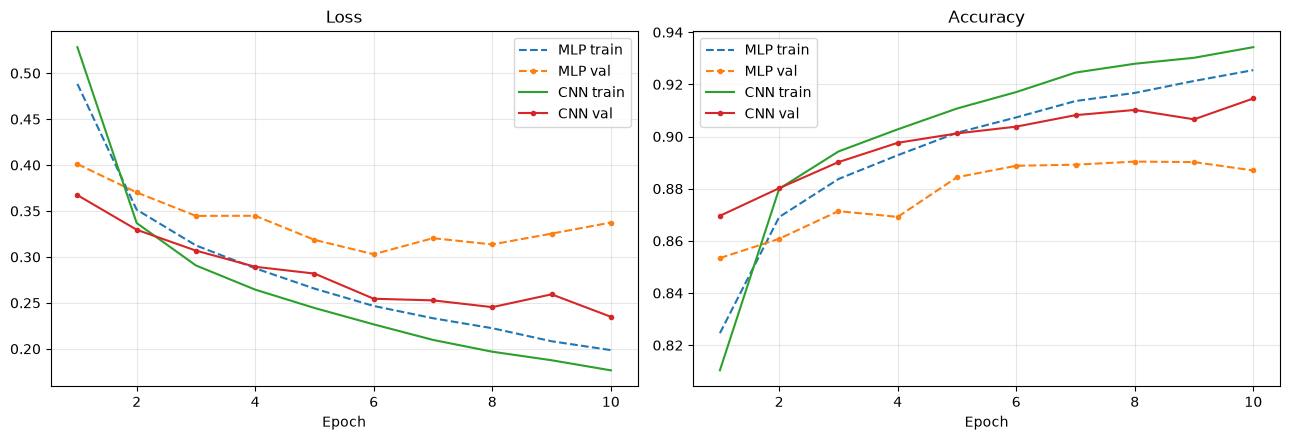

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, EPOCHS + 1)

for name, h, style in [("MLP", mlp_hist, "--"), ("CNN", cnn_hist, "-")]:
    axes[0].plot(epochs_range, h["train_loss"], style, label=f"{name} train")
    axes[0].plot(epochs_range, h["val_loss"], style, marker="o", markersize=3, label=f"{name} val")
    axes[1].plot(epochs_range, h["train_acc"], style, label=f"{name} train")
    axes[1].plot(epochs_range, h["val_acc"], style, marker="o", markersize=3, label=f"{name} val")

axes[0].set_title("Loss"); axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Final comparison (test set used once)

In [9]:
criterion = nn.CrossEntropyLoss()
mlp_test_loss, mlp_test_acc = run_epoch(mlp, test_loader, criterion)
cnn_test_loss, cnn_test_acc = run_epoch(cnn, test_loader, criterion)

print(f"{'Model':<6} {'Params':>10} {'Val acc':>9} {'Test acc':>9} {'Train time (s)':>15}")
print(f"{'MLP':<6} {count_params(mlp):>10,} {mlp_hist['val_acc'][-1]:>9.4f} {mlp_test_acc:>9.4f} {mlp_hist['time']:>15.1f}")
print(f"{'CNN':<6} {count_params(cnn):>10,} {cnn_hist['val_acc'][-1]:>9.4f} {cnn_test_acc:>9.4f} {cnn_hist['time']:>15.1f}")

Model      Params   Val acc  Test acc  Train time (s)
MLP       235,146    0.8870    0.8881           238.7
CNN       105,866    0.9146    0.9120           436.1


## Summary (rewrite in your own words)
- `DataLoader` feeds the data in mini-batches, and the model and every batch must be moved to the same device with `.to(device)`.
- The MLP flattens the image and loses spatial information; the CNN keeps it using local filters and shared weights.
- Compare the table above: the CNN should reach a higher accuracy, and here with fewer parameters than the MLP.
- Always track the tensor shape after each layer, because the size of the first `Linear` layer depends on it.
- Next (Day 3): add batch norm and dropout, plot a confusion matrix and visualise the learned filters.